# Lab 1: Claims Risk Scoring

**Time:** about 75 minutes

Every claim the Fund pays is checked later by an audit sample, and about one in eleven audited claims turns
out to be irregular: an overpayment, a claim that shouldn't have been approved, false documents,
occasionally fraud. By then the money has gone, and recovering it is slow and often unsuccessful.

The review team could check claims **before** payment instead, but they can't check them all. They need a
way to put the riskiest claims at the top of the pile. That's what you'll build: a model that gives each
new claim a **risk score** between 0 and 1.

```
claims history ─► explore ─► features ─► split by time ─► baseline ─► logistic regression
                                                              ─► decision tree ─► XGBoost ─► risk scores
```

You'll deliberately start simple and add complexity only when it earns its place.

## Where this lab fits

**What you've done so far.** On Day 1 you explored the Fund's raw data, wrote down its problems, and built a pipeline
that cleans it the same way every time. You've *described* the data. You haven't asked it to *predict* anything yet.

**What you'll do now.** You'll build your first machine learning model. It learns from about 7,800 claims that have
already been audited, and gives each new claim a **risk score**: how likely it is that an audit would find a problem.
You'll start with the simplest possible model and add complexity only when it clearly earns its place.

**Why it matters.** The review team can only check a small share of claims before payment. Today they pick them by
experience and rules of thumb. A good score puts the riskiest claims at the top of the pile, so the same team catches
more problems before the money goes out.

**What happens next.** Lab 2 asks a different kind of question (what groups of members and employers exist?) with
no "right answer" to learn from. Lab 3 comes back to this model and tests it much more carefully: against the review
team's real capacity, across several years, for fairness, and for a trap that makes models look far better than they
are.

### Theory: what "machine learning" means here

In ordinary programming you write the rules: *"if the bank details changed in the last 60 days and documents are
missing, flag the claim"*. In **machine learning** you give the computer many examples where you already know the
answer, and it works out the rules itself.

The vocabulary:

| Word | Meaning in this lab |
|---|---|
| **example** (row) | one past claim |
| **features** (inputs, `X`) | what was known about the claim when it was lodged: amount, channel, documents missing, ... |
| **target** (label, `y`) | what we want to predict: `irregular`, 1 if the audit found a problem, 0 if not |
| **training** | showing the model the examples so it can learn how the features relate to the target |
| **model** | the learned rules, in whatever form the method uses (weights, a tree of questions, ...) |
| **prediction** / **score** | the model's output for a new claim it hasn't seen |

This is **supervised learning** (the examples come with answers) and, because the target has two possible values,
it's a **classification** problem. Most classification models don't just say yes or no: they give a number between 0
and 1, read as *"how likely is a 1"*. That number is the risk score.

**What a model can't do.** It only learns patterns that are in the examples. If the past audits never looked at a
certain kind of fraud, the model can't learn to spot it. And it learns whatever was in the data, including the habits
and blind spots of whoever chose which claims to audit.

## 0. Set up today's environment (run this cell first)

You don't need to create a folder or an environment by hand today. The cell below does it for you:

1. It finds the environment you created on Day 1 (`DAY1/Labs/work/fund-ai/.venv`). If it isn't there, it creates it.
2. It installs today's libraries into it from ``requirements.txt``. The first time takes a few minutes; after that, seconds.
3. It connects the environment to Jupyter as **Python (fund-ai)**, and tells you if this notebook isn't using it yet.

It's safe to run again at any time. If it prints instructions to switch the kernel, follow them and run it once more.

You don't need to read the code in this cell. It's housekeeping, not part of today's lesson.

In [8]:
# ---- Setup for Day 2. Safe to run more than once. -------------------------------------------------------------
COURSE_ENV = None        # None = use the Day 1 environment. Or set a folder, e.g. Path.home() / "fund-ai-venv"
REQUIREMENTS = "requirements.txt"
EXTRAS = []

import os, shutil, subprocess, sys
from pathlib import Path

labs = Path.cwd()
root = next((p for p in [labs, *labs.parents] if (p / "DAY1").is_dir()), None)
if root is None:
    raise RuntimeError("Open this notebook from inside the course folder (the one that contains DAY1, DAY2, ...).")
env = Path(COURSE_ENV) if COURSE_ENV else root / "DAY1" / "Labs" / "work" / "fund-ai" / ".venv"
py = env / ("Scripts/python.exe" if os.name == "nt" else "bin/python")


def run(*cmd, quiet=False):
    """Run a command; show its output only if it fails."""
    r = subprocess.run([str(c) for c in cmd], capture_output=True, text=True)
    if r.returncode != 0 and not quiet:
        print(r.stdout[-3000:], r.stderr[-3000:])
        if "path" in (r.stderr + r.stdout).lower() and os.name == "nt":
            print("\nIf the error mentions a path that is too long: Windows 'long paths' are switched off on this machine.\n"
                  "Ask ICT to enable them, or set COURSE_ENV above to a short folder, e.g. Path.home() / 'fund-ai-venv'.")
        raise RuntimeError("A setup step failed. The details are printed above.")
    return r


# 1. The course environment
if py.exists():
    print(f"- course environment found: {env}")
else:
    print(f"- creating the course environment (first time only): {env}")
    run(getattr(sys, "_base_executable", sys.executable), "-m", "venv", env)
    run(py, "-m", "pip", "install", "-q", "--upgrade", "pip")

# 2. Today's libraries
req = labs / REQUIREMENTS
print(f"- installing today's libraries from {REQUIREMENTS} ...")
run(py, "-m", "pip", "install", "-q", "-r", req)

# 3. Use the GPU if this machine has an NVIDIA one
if "torch" in req.read_text() and shutil.which("nvidia-smi"):
    if run(py, "-c", "import torch; print(torch.cuda.is_available())").stdout.strip() != "True":
        version = run(py, "-c", "import torch; print(torch.__version__.split('+')[0])").stdout.strip()
        print(f"- NVIDIA GPU found: switching PyTorch {version} to its GPU build (about 2.5 GB, first time only) ...")
        run(py, "-m", "pip", "uninstall", "-y", "-q", "torch")
        run(py, "-m", "pip", "install", "-q", f"torch=={version}", "--index-url", "https://download.pytorch.org/whl/cu124",
            "--extra-index-url", "https://pypi.org/simple")
    print("- PyTorch will use the GPU")

# 4. Anything else today needs
for extra in EXTRAS:
    kind, name = extra.split(":", 1)
    if kind == "spacy" and run(py, "-c", f"import {name}", quiet=True).returncode != 0:
        print(f"- downloading the spaCy model {name} ...")
        run(py, "-m", "spacy", "download", name)
    if kind == "ollama":
        import json, urllib.request
        try:
            tags = json.load(urllib.request.urlopen("http://localhost:11434/api/tags", timeout=3))["models"]
            have = {m["name"] for m in tags}
            wanted = [m for m in name.split(",") if m]
            missing = [m for m in wanted if m not in have]
            print(f"- Ollama is running with {len(have)} model(s)" + (f"; still to pull: {', '.join(missing)}" if missing else ""))
            for m in missing:
                print(f"    in a terminal: ollama pull {m}")
        except OSError:
            print("- Ollama isn't running. Start the Ollama app (or run `ollama serve` in a terminal) before the LLM parts.")

# 5. Connect the environment to Jupyter
run(py, "-m", "ipykernel", "install", "--user", "--name", "fund-ai", "--display-name", "Python (fund-ai)")

# 6. Is this notebook using it?
if Path(sys.prefix).resolve() == env.resolve():
    print("\nReady. This notebook is running in the course environment. Carry on with the next cell.")
else:
    print("\nAlmost there. This notebook is running a different Python:")
    print(f"    {sys.executable}")
    print("Switch it to the course environment, then run this cell once more:")
    print("    1. Click the kernel name in the top right of the notebook, then 'Select Another Kernel'.")
    print("    2. Choose 'Jupyter Kernel' -> 'Python (fund-ai)'.")
    print("       (Or press Ctrl+Shift+P, run 'Python: Select Interpreter', choose 'Enter interpreter path...'")
    print("        and paste the path below, the same way you did on Day 1.)")
    print(f"    {py}")

- course environment found: /Users/daud.mabena/Documents/DUBAI/Training1910Labs/DAY1/Labs/work/fund-ai/.venv
- installing today's libraries from requirements.txt ...

Ready. This notebook is running in the course environment. Carry on with the next cell.


## Imports

In [9]:
import os
import warnings

# Windows 11 no longer has the "wmic" tool that some libraries use to count CPU cores, and they print a long
# (harmless) error about it. Telling them how many cores to use skips that check.
os.environ["LOKY_MAX_CPU_COUNT"] = str(os.cpu_count() - 1)

# Hide "this will change in a future version" notices from the libraries.
warnings.filterwarnings("ignore", category=FutureWarning)

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
# scikit-learn: the standard Python library for classic machine learning.
from sklearn.model_selection import train_test_split     # split data into training and test sets
from sklearn.compose import ColumnTransformer            # apply different preparation to different columns
from sklearn.pipeline import Pipeline                    # chain preparation steps and a model together
from sklearn.impute import SimpleImputer                 # fill in missing values
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyClassifier                # a "model" that guesses, as a baseline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import roc_auc_score, average_precision_score, confusion_matrix, RocCurveDisplay

# XGBoost: a separate library for gradient-boosted trees. On macOS, if `import xgboost` fails, run `brew install libomp`.
from xgboost import XGBClassifier

In [11]:
# Show more columns when printing tables.
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)

# The "random seed": any number works. Using the same one every time makes random steps repeatable.
SEED = 42

> **Where we are.** The libraries are loaded. Before building anything, you'll get to know this table the way you got
> to know the Day 1 tables: what each column means, what the target looks like, what's missing and why.

## 1. Meet the data

In [12]:
# Read the claims history. parse_dates turns claim_date into a real date.
claims = pd.read_csv("claims_review_history.csv", parse_dates=["claim_date"], dtype={"claim_no": "string"})
print(claims.shape)
claims.head()

(7816, 21)


,claim_no,claim_date,benefit_type,channel,branch,gender,member_age,employer_sector,months_contributed,months_contributed_last_12,avg_wage_last_6m_tzs,amount_claimed_tzs,employer_arrears_months_12m,days_since_registration,previous_claims,days_since_last_claim,documents_missing_at_lodging,bank_details_changed_days_ago,irregular,investigation_opened,amount_recovered_tzs
0,CLM-2019-005221,2019-01-01,UNEMPLOYMENT,BRANCH,Ubungo,F,32.0,Security Services,45,10,506000.0,1011000.0,7,1392,0,NaN,2.0,241.0,0,0,0.0
1,CLM-2019-006887,2019-01-02,FUNERAL_GRANT,BRANCH,Morogoro,M,48.1,Agriculture,309,9,582000.0,500000.0,0,9453,0,NaN,0.0,NaN,0,0,0.0
2,CLM-2019-001935,2019-01-02,UNEMPLOYMENT,BRANCH,Pwani,M,33.0,Hospitality & Tourism,60,10,608000.0,1214800.0,0,1903,0,NaN,0.0,NaN,0,0,0.0
3,CLM-2019-000379,2019-01-03,UNEMPLOYMENT,BRANCH,Temeke,M,28.1,Manufacturing,19,9,654000.0,1306700.0,4,401,0,NaN,0.0,NaN,0,0,0.0
4,CLM-2019-013483,2019-01-03,UNEMPLOYMENT,BRANCH,Kagera,M,41.1,Manufacturing,65,8,639000.0,1276700.0,0,2046,0,NaN,0.0,NaN,0,0,0.0


| Column | Meaning |
|---|---|
| `benefit_type`, `channel`, `branch` | What was claimed, how it came in (BRANCH, ONLINE, EMPLOYER_HR), and where |
| `member_age`, `gender`, `employer_sector` | About the member |
| `months_contributed`, `months_contributed_last_12` | Contribution history at the time of the claim |
| `avg_wage_last_6m_tzs`, `amount_claimed_tzs` | Recent wage and the amount claimed |
| `employer_arrears_months_12m` | How many of the last 12 months the employer paid late or not at all |
| `days_since_registration` | How long the member had been registered when they claimed |
| `previous_claims`, `days_since_last_claim` | The member's claim history |
| `documents_missing_at_lodging` | Documents missing when the claim was lodged |
| `bank_details_changed_days_ago` | Days since the member's bank details were last changed (empty = not changed in the last two years) |
| `irregular` | **Target.** 1 = the audit found a problem |
| `investigation_opened`, `amount_recovered_tzs` | Filled in *after* the audit. You will **not** use these today. |

Look at the target first. Always.

### Theory: two columns you must never use, and why

`investigation_opened` and `amount_recovered_tzs` would make the model look superb. They're also useless, because
they're only filled in **after** the audit. When a new claim arrives, nobody knows yet whether an investigation will be
opened.

Using information that won't exist at the moment of prediction is called **data leakage**. A leaked column lets the
model "see the answer", so its test results look wonderful, and then it fails completely in real use. The test is
simple: for every feature, ask *"would I know this value at the moment I need the score?"*. If not, it goes.

You'll fall into this trap on purpose in Lab 3, so you recognise it when it happens by accident.

Now, as the table says: look at the target first.

In [18]:
# How many claims are regular (0) and irregular (1)?
claims["irregular"].value_counts()


irregular
0    7093
1     723
Name: count, dtype: int64

In [30]:
# The mean of a 0/1 column is the share of 1s.
irregular_rate = claims["irregular"].mean()
print(f"Irregular rate: {irregular_rate:.2%}")
print(f"Regular rate: {1 - irregular_rate:.2%}")

Irregular rate: 9.25%
Regular rate: 90.75%


### Theory: imbalanced classes, and why accuracy misleads

When one answer is much rarer than the other (here about 9 irregular claims in every 100), the data is called
**imbalanced**. Imbalance changes how you have to judge a model.

**Accuracy** is the share of predictions that are right. It sounds like the obvious measure, but look what happens
with 100 claims, 9 of them irregular:

| "Model" | Correct | Accuracy | Irregular claims caught |
|---|---|---|---|
| says "regular" for every claim | 91 | 91% | 0 |
| a useful model that flags 15 claims, 7 of them irregular | 83 + 7 = 90 | 90% | 7 of 9 |

The useless model has the *higher* accuracy. With imbalanced data, accuracy mostly measures how rare the problem is.
That's why this lab uses measures that focus on the rare class (precision, recall, ROC-AUC, PR-AUC), explained in
Section 6.

About 9% of claims are irregular. That imbalance has a consequence you should see straight away. A
"model" that says *every* claim is fine would be right 91% of the time:

In [31]:
print(f"Accuracy of always predicting 'regular': {1 - irregular_rate:.1%}")

Accuracy of always predicting 'regular': 90.7%


91% accuracy, and it catches zero irregular claims. From now on, accuracy is not your headline metric.
You'll use precision, recall and ROC-AUC (area under the ROC curve: 0.5 = guessing, 1 = perfect ranking), and in Lab 3 a measure tied directly to the review team's
capacity.

### Missing values: which ones carry meaning?

In [33]:
# Share of missing values in each column, keeping only the columns that have some.
missing_share = claims.isna().mean()
missing_share = missing_share[missing_share > 0]
missing_share.sort_values(ascending=False)

days_since_last_claim            0.894831
bank_details_changed_days_ago    0.706883
member_age                       0.019959
avg_wage_last_6m_tzs             0.015225
documents_missing_at_lodging     0.009980
dtype: float64

Two kinds of missing here, and they need different treatment:

- **Structural.** `days_since_last_claim` is empty because the member has **no** previous claim.
  `bank_details_changed_days_ago` is empty because the details **weren't** changed. The blank *is*
  information. You'll turn it into a yes/no feature rather than filling it with an average.
- **Random gaps.** A few `member_age`, `avg_wage_last_6m_tzs` and `documents_missing_at_lodging` values
  simply weren't captured. Those you'll impute, with values learned from the training data only.

In [34]:
# Check: is days_since_last_claim empty exactly when previous_claims is 0?
no_last_claim = claims["days_since_last_claim"].isna()
no_previous_claims = claims["previous_claims"] == 0
print("Always the same rows:", (no_last_claim == no_previous_claims).all())

Always the same rows: True


### A quick look for signal

Before modelling, check whether anything in the data relates to the target at all. If nothing does, no
algorithm will rescue you. Each chart below shows the share of irregular claims in each group.

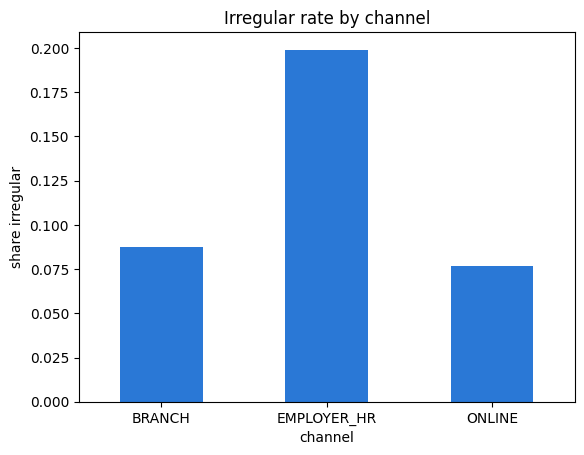

In [35]:
# Irregular rate by channel.
rate_by_channel = claims.groupby("channel")["irregular"].mean()

rate_by_channel.plot(kind="bar", color="#2a78d6")
plt.title("Irregular rate by channel")
plt.ylabel("share irregular")
plt.xticks(rotation=0)
plt.show()

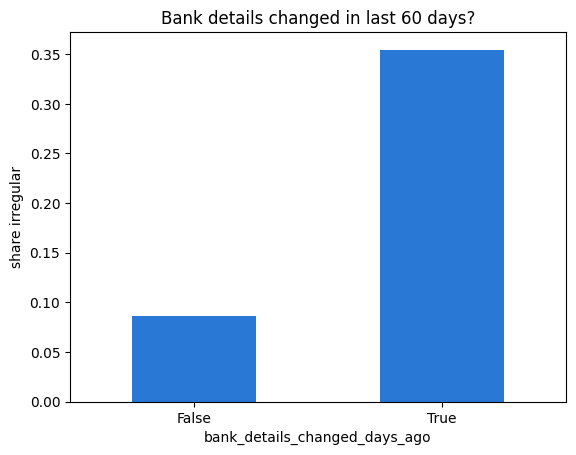

In [36]:
# Were the bank details changed in the 60 days before the claim? (True / False)
bank_changed_recently = claims["bank_details_changed_days_ago"] <= 60

rate_by_bank_change = claims.groupby(bank_changed_recently)["irregular"].mean()

rate_by_bank_change.plot(kind="bar", color="#2a78d6")
plt.title("Bank details changed in last 60 days?")
plt.ylabel("share irregular")
plt.xticks(rotation=0)
plt.show()

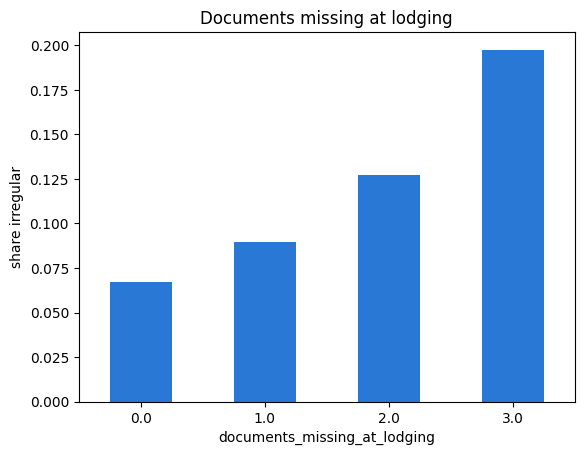

In [37]:
# Irregular rate by the number of documents missing when the claim was lodged.
rate_by_documents = claims.groupby("documents_missing_at_lodging")["irregular"].mean()

rate_by_documents.plot(kind="bar", color="#2a78d6")
plt.title("Documents missing at lodging")
plt.ylabel("share irregular")
plt.xticks(rotation=0)
plt.show()

> **Where we are.** You know the target (about 9% irregular), which blanks carry meaning, and that some features
> (recent bank changes, missing documents, the HR channel) already show a link with irregular claims. Now you'll turn
> those observations into columns the model can use.

### Theory: feature engineering

A **feature** is a column the model learns from. **Feature engineering** means creating new features that make a
pattern easier to see. Models are good at combining features, but they're not good at inventing them. A claims officer
looks at a TZS 6 million claim from a member earning TZS 300,000 a month and thinks "that's twenty times their wage".
The model only sees two separate numbers unless you give it the ratio.

Good features usually come from people who know the work. Each feature below has a one-line reason a claims officer
would recognise.

**Structural blanks as features.** When a blank means "this never happened" (no previous claim, bank details never
changed), the fact that it's blank is information. Turning it into a yes/no column (`has_previous_claim`) keeps that
information. Filling the blank with an average would erase it.

There's signal. A recent change of bank details stands out. If you've worked in benefits, you know why:
redirecting a payment to a new account is one of the oldest tricks there is. Claims lodged by an employer's
HR office and claims with missing documents also carry more risk.

## 2. Features

A handful of engineered features, each with a reason:

- `amount_to_wage_ratio`: a claim that's large *relative to the member's own wage* is more telling than a
  large claim on its own.
- `bank_changed_60d`: the pattern you just saw, made explicit.
- `has_previous_claim` and `bank_ever_changed`: turn the structural blanks into information.

Each feature uses only the values **in the same row**: it never looks at other claims and never looks at the target.
That makes it safe to create them now, before splitting the data. (Anything that *learns* from the data, like
filling gaps with a median, must wait until after the split. You'll see that in Section 4.)

In [38]:
# How big is the claim compared with the member's own monthly wage?
claims["amount_to_wage_ratio"] = claims["amount_claimed_tzs"] / claims["avg_wage_last_6m_tzs"]

# Were the bank details ever changed? (1 = yes, 0 = no). astype(int) turns True/False into 1/0.
claims["bank_ever_changed"] = claims["bank_details_changed_days_ago"].notna().astype(int)

# Were they changed in the last 60 days?
claims["bank_changed_60d"] = (claims["bank_details_changed_days_ago"] <= 60).astype(int)

# Has the member claimed before?
claims["has_previous_claim"] = (claims["previous_claims"] > 0).astype(int)

In [39]:
# Fill the structural blanks with 9999, meaning "a very long time ago".
claims["days_since_last_claim"] = claims["days_since_last_claim"].fillna(9999)
claims["bank_details_changed_days_ago"] = claims["bank_details_changed_days_ago"].fillna(9999)

# Claim amounts are very skewed. log1p(x) = log(1 + x) squeezes very large amounts together and is safe at 0.
claims["log_amount"] = np.log1p(claims["amount_claimed_tzs"])

claims[["amount_claimed_tzs", "log_amount", "amount_to_wage_ratio", "bank_changed_60d", "has_previous_claim"]].head()

,amount_claimed_tzs,log_amount,amount_to_wage_ratio,bank_changed_60d,has_previous_claim
0,1011000.0,13.826451,1.998024,0,0
1,500000.0,13.122365,0.859107,0,0
2,1214800.0,14.010091,1.998026,0,0
3,1306700.0,14.083016,1.998012,0,0
4,1276700.0,14.059790,1.997966,0,0


In [40]:
# The columns the model will use: numbers...
NUMERIC = [
    "member_age", "months_contributed", "months_contributed_last_12", "log_amount", "amount_to_wage_ratio",
    "employer_arrears_months_12m", "days_since_registration", "previous_claims", "days_since_last_claim",
    "documents_missing_at_lodging", "bank_details_changed_days_ago", "bank_ever_changed", "bank_changed_60d",
    "has_previous_claim",
]
# ...and categories (text).
CATEGORICAL = ["benefit_type", "channel", "employer_sector", "gender"]

FEATURES = NUMERIC + CATEGORICAL
print(len(FEATURES), "features")

18 features


### Theory: why you test on data the model hasn't seen

A model can do well on the examples it learned from simply by memorising them, the way a student can memorise last
year's exam answers without understanding the subject. What you care about is how it does on **new** claims. That
ability is called **generalisation**.

So you split the data in two:

- the **training set** is what the model learns from;
- the **test set** is kept locked away and used once, at the end, to measure the model on claims it never saw.

If you check the test set over and over while tuning, you slowly tune the model to the test set itself, and its score
stops being an honest estimate. Treat the test set like a sealed exam paper.

**Splitting by time.** When rows have dates and the model will be used on the future, the honest split copies that:
learn from the past, test on a later period. A random split lets the model peek at 2025 patterns while being tested on
2024 claims, which it will never be able to do in real use.

`branch` is left out on purpose. It has many values with few claims each, and a model that learns "claims
from branch X are risky" can end up scoring members by where they live. That's worth discussing with the
business before it goes anywhere near a model.

## 3. Training and test sets

A model is judged on claims it has **never seen**. So you keep some claims aside as a **test set**, train on the
rest, and only look at the test set at the very end.

### The standard way: `train_test_split`

scikit-learn's `train_test_split` does this in one line. `test_size=0.2` keeps 20% of the rows for testing.
`stratify` makes sure both parts get the same share of irregular claims. `random_state` makes the split repeatable.

In [41]:
X = claims[FEATURES]          # the inputs
y = claims["irregular"]       # the answer we want the model to predict

X_train_random, X_test_random, y_train_random, y_test_random = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED
)

print("training rows:", len(X_train_random), " irregular rate:", round(y_train_random.mean(), 3))
print("test rows:    ", len(X_test_random), " irregular rate:", round(y_test_random.mean(), 3))

training rows: 6252  irregular rate: 0.092
test rows:     1564  irregular rate: 0.093


That's the split you'll use most often, and it's right whenever the rows don't have an order in time.

### For this problem: split by date

Claims do have an order in time, and the model will be used on **future** claims. A random split lets the model
learn from claims lodged *after* the ones it's tested on, which flatters it. So test it the way it will be used:
train on the claims up to the end of 2024 and test on 2025, a period it has never seen.

In [42]:
# Claims before 2025 for training, claims from 2025 for testing.
is_train = claims["claim_date"] < "2025-01-01"
is_test = claims["claim_date"] >= "2025-01-01"

train = claims[is_train]
test = claims[is_test]

print("train:", len(train), "claims from", train["claim_date"].min().date(), "to", train["claim_date"].max().date())
print("test: ", len(test), "claims from", test["claim_date"].min().date(), "to", test["claim_date"].max().date())

train: 6476 claims from 2019-01-01 to 2024-12-31
test:  1340 claims from 2025-01-01 to 2026-01-27


In [43]:
# Separate the inputs (X) from the answer (y), for both sets. This is the split you'll use from here on.
X_train = train[FEATURES]
y_train = train["irregular"]

X_test = test[FEATURES]
y_test = test["irregular"]

print("irregular rate, train:", round(y_train.mean(), 3))
print("irregular rate, test: ", round(y_test.mean(), 3))

irregular rate, train: 0.092
irregular rate, test:  0.096


> **Where we are.** You have training claims (up to the end of 2024) and test claims (2025), each split into features
> `X` and target `y`. The features still have gaps and text columns, and models need complete numbers. On Day 1
> (Lab 3, Section 9) you saw the preparation steps; now you'll use them for real.

## 4. Preparing the data for a model

Models need numbers with no gaps. Three preparation steps:

1. **Fill the gaps** (imputation): a missing age gets the median age, a missing category gets the most common one.
2. **Scale the numbers** to a similar range (mean 0, spread 1), so a wage in millions doesn't drown out an age in
   tens. Logistic regression needs this; tree models don't.
3. **One-hot encode** the text columns.

The values these steps use (the median age, the mean wage) must be learned from the **training data only**. Putting the
steps in a `Pipeline` with the model guarantees that: when you call `fit` on the training data, every step learns
from it, and the test set stays untouched until evaluation.

### What one-hot encoding does

A model can only do arithmetic with numbers, so a text column like `channel` has to be turned into numbers first.
One-hot encoding gives each possible value its own 0/1 column:

```
channel        channel_BRANCH  channel_EMPLOYER_HR  channel_ONLINE
BRANCH    ->         1                 0                  0
ONLINE    ->         0                 0                  1
```

Why not simply number them 1, 2, 3? Because the model would read "ONLINE (3) is three times BRANCH (1)", which means
nothing. Separate 0/1 columns make no such claim.

In [44]:
# See one-hot encoding on its own, on the first five claims.
encoder = OneHotEncoder()
encoded = encoder.fit_transform(claims[["channel"]].head())

pd.DataFrame(encoded.toarray(), columns=encoder.get_feature_names_out())

,channel_BRANCH
0,1.0
1,1.0
2,1.0
3,1.0
4,1.0


You'll build the same preparation for several models, so write it once as a function. It returns a fresh set of steps
each time, so two models never share (and overwrite) each other's learned values.

In [45]:
def make_preprocessor(scale_numbers):
    """The preparation steps for our features. scale_numbers=True for logistic regression, False for trees."""
    # Steps for the number columns.
    if scale_numbers:
        numeric_steps = Pipeline([
            ("impute", SimpleImputer(strategy="median")),
            ("scale", StandardScaler()),
        ])
    else:
        numeric_steps = Pipeline([
            ("impute", SimpleImputer(strategy="median")),
        ])

    # Steps for the text columns. handle_unknown="ignore": a category never seen in training gets all zeros.
    category_steps = Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ])

    # Apply each set of steps to its own columns.
    return ColumnTransformer([
        ("num", numeric_steps, NUMERIC),
        ("cat", category_steps, CATEGORICAL),
    ])

> **Where we are.** The preparation steps are packed into one function, `make_preprocessor`. From here on, every model
> is "preparation + model" in a single pipeline, trained on 2019-2024 and tested on 2025.

### Theory: why every project needs a baseline

A **baseline** is the simplest possible answer to the problem. Its job is to tell you what "no skill" looks like, so
that you know whether your model has any.

Without a baseline, numbers are hard to read. Is a PR-AUC of 0.3 good? If random guessing gives 0.09, then yes, it's
three times better than guessing. If a one-line rule gives 0.35, then your model is worse than the rule.

The baseline here guesses "irregular" at random for about 9% of claims. Every real model must beat it clearly, and
ideally also beat a simple human rule of thumb.

## 5. A baseline to beat

Start with a model that knows nothing: it guesses at random in proportion to the classes. Any real model
must beat it clearly, or it isn't worth the trouble.

In [46]:
# strategy="stratified": guess "irregular" about 9% of the time, at random.
baseline = DummyClassifier(strategy="stratified", random_state=SEED)
baseline.fit(X_train, y_train)

# predict_proba gives two columns: P(regular) and P(irregular). [:, 1] keeps the second one, the risk score.
baseline_scores = baseline.predict_proba(X_test)[:, 1]

print("ROC-AUC:", round(roc_auc_score(y_test, baseline_scores), 3))
print("PR-AUC: ", round(average_precision_score(y_test, baseline_scores), 3))

ROC-AUC: 0.491
PR-AUC:  0.095


### Theory: how logistic regression turns features into a probability

Logistic regression works in two steps.

**Step 1: a weighted sum.** Each feature gets a **weight** (a number the model learns). Multiply each feature by its
weight and add them up, plus a starting value:

```
total = start + (weight_1 × bank_changed_60d) + (weight_2 × documents_missing) + ...
```

A positive weight means "more of this feature, more risk"; a negative weight means less risk; a weight near zero means
the feature doesn't matter.

**Step 2: squash it into 0-1.** The total can be any number, like -3.2 or 4.7. The **sigmoid** function squeezes it
into a probability between 0 and 1:

| total | -4 | -2 | 0 | 2 | 4 |
|---|---|---|---|---|---|
| probability | 0.02 | 0.12 | 0.50 | 0.88 | 0.98 |

**How it learns.** Training adjusts the weights, again and again, so that irregular claims in the training data get
probabilities close to 1 and regular claims probabilities close to 0.

**Why scaling matters for it.** Because every feature is multiplied by a weight, a feature measured in millions
(wages) and one measured in units (documents missing) would need weights of very different sizes. Scaling all numbers
to the same range lets the model learn the weights fairly.

**Class weights.** With 9% irregular claims, the model can get its error quite low by mostly ignoring them.
`class_weight="balanced"` makes each mistake on an irregular claim count about ten times as much as a mistake on a
regular one, so the model has to take them seriously.

ROC-AUC of about 0.5 is a coin toss. PR-AUC (average precision) of a random model is simply the share of
irregular claims, about 0.09. Those are your floors.

## 6. Logistic regression

Logistic regression is fast, stable, and easy to explain: every feature gets one weight, and you can read
off whether it pushes risk up or down. It's the model to beat.

`class_weight="balanced"` tells it to take the rare class seriously. Without it, the easiest way for the
model to reduce its error is to ignore irregular claims altogether.

In [47]:
# Preparation + model in one pipeline.
logreg = Pipeline([
    ("prep", make_preprocessor(scale_numbers=True)),
    ("model", LogisticRegression(max_iter=2000, class_weight="balanced")),
])

# Train on the training data only.
logreg.fit(X_train, y_train)

# Risk scores for the test claims.
p_lr = logreg.predict_proba(X_test)[:, 1]
p_lr[:5]

array([0.30379289, 0.63098443, 0.43059526, 0.5949586 , 0.3695576 ])

### Theory: the confusion matrix, and the measures built from it

Once you turn scores into yes/no decisions (here: score 0.5 or more = flagged), every test claim lands in one of four
boxes:

| | model says **regular** | model says **irregular** (flagged) |
|---|---|---|
| **really regular** | true negative (TN): correctly left alone | false positive (FP): checked for nothing |
| **really irregular** | false negative (FN): **missed** | true positive (TP): **caught** |

That table is the **confusion matrix**. The measures are simple ratios of its boxes:

- **precision** = TP / (TP + FP): of the claims the team checks, how many are real problems? *Low precision wastes
  reviewers' time.*
- **recall** = TP / (TP + FN): of all the real problems, how many does the team catch? *Low recall loses money.*
- **F1** combines them into one number, high only when both are high.

There's always a trade-off. Lower the threshold and you flag more claims: recall goes up, precision goes down.

**ROC-AUC and PR-AUC don't need a threshold.** They look at the ranking itself. ROC-AUC is the chance that a randomly
picked irregular claim gets a higher score than a randomly picked regular one: 0.5 is a coin toss, 1.0 is perfect.
PR-AUC (average precision) focuses on the top of the ranking, which is where the review team works, and is the more
demanding measure when the problem class is rare.

Now measure it. Each metric answers a different question:

- **accuracy**: what share of yes/no decisions were right? (Misleading here, as you saw.)
- **precision**: of the claims flagged, what share were really irregular?
- **recall**: of all irregular claims, what share were flagged?
- **F1**: one number balancing precision and recall.
- **ROC-AUC** and **PR-AUC**: how well the *scores* rank irregular claims above regular ones, at any threshold.

The first four need yes/no decisions, so turn the scores into decisions at a threshold of 0.5.

In [48]:
# Score of 0.5 or more = flagged (1), otherwise not (0).
flagged_lr = (p_lr >= 0.5).astype(int)

print("accuracy: ", round(accuracy_score(y_test, flagged_lr), 3))
print("precision:", round(precision_score(y_test, flagged_lr), 3))
print("recall:   ", round(recall_score(y_test, flagged_lr), 3))
print("F1:       ", round(f1_score(y_test, flagged_lr), 3))
print("ROC-AUC:  ", round(roc_auc_score(y_test, p_lr), 3))
print("PR-AUC:   ", round(average_precision_score(y_test, p_lr), 3))

accuracy:  0.754
precision: 0.226
recall:    0.643
F1:        0.335
ROC-AUC:   0.743
PR-AUC:    0.326


You'll compute the same six numbers for every model, so put them in a small function and keep the results in one
table.

In [49]:
def scores(y_true, risk_scores, threshold=0.5):
    """The six metrics for one model, as a dictionary."""
    flagged = (risk_scores >= threshold).astype(int)
    return {
        "accuracy": accuracy_score(y_true, flagged),
        "precision": precision_score(y_true, flagged, zero_division=0),
        "recall": recall_score(y_true, flagged),
        "f1": f1_score(y_true, flagged),
        "roc_auc": roc_auc_score(y_true, risk_scores),
        "pr_auc": average_precision_score(y_true, risk_scores),
    }


# A dictionary of results: model name -> its scores.
results = {}
results["random baseline"] = scores(y_test, baseline_scores)
results["logistic regression"] = scores(y_test, p_lr)

pd.DataFrame(results).T.round(3)

,accuracy,precision,recall,f1,roc_auc,pr_auc
random baseline,0.825,0.080,0.078,0.079,0.491,0.095
logistic regression,0.754,0.226,0.643,0.335,0.743,0.326


A big jump over the baseline. Now look at *what kind* of mistakes it makes, at the default threshold of 0.5:

In [50]:
# Rows = what really happened, columns = what the model said.
cm = confusion_matrix(y_test, flagged_lr)
pd.DataFrame(cm, index=["actual regular", "actual irregular"], columns=["flagged: no", "flagged: yes"])

,flagged: no,flagged: yes
actual regular,927,284
actual irregular,46,83


> **Where we are.** Logistic regression beats the baseline by a wide margin. But it treats each feature separately:
> it can't easily learn "this is risky only when *both* of these are true". Trees can.

### Theory: how a decision tree learns

A **decision tree** is a flowchart of yes/no questions. To build it, the algorithm looks at every feature and every
possible cut-off and asks: *"which single question best separates the irregular claims from the regular ones?"*. For
example, *"bank details changed in the last 60 days?"* might split the claims into one group with 30% irregular and
another with 6%. It picks the best question, then repeats the search inside each group, and so on.

The end points are called **leaves**. A claim's score is the share of irregular training claims in the leaf it lands
in.

**Overfitting.** Left to grow without limits, a tree keeps asking questions until every leaf holds a handful of
claims, all of one kind. It has then memorised the training data, noise and all, and does worse on new claims. Two
settings stop that: `max_depth` limits how many questions can be asked in a row, and `min_samples_leaf` requires every
leaf to contain enough claims to mean something.

Read it as the review team would. The right-hand column is the pile of claims they'd have to check. It
catches most of the irregular claims, but the pile is huge and most of what's in it is fine. The threshold
of 0.5 wasn't chosen with the team's capacity in mind. You'll fix that properly in Lab 3.

## 7. A decision tree

A tree asks a series of yes/no questions. It can capture interactions the logistic regression can't (for
example, "a recent bank change **and** an online claim"), and a small one can be drawn and explained on a
whiteboard.

In [51]:
# max_depth=4: at most 4 questions in a row. min_samples_leaf=50: every final group has at least 50 claims.
tree = Pipeline([
    ("prep", make_preprocessor(scale_numbers=False)),
    ("model", DecisionTreeClassifier(max_depth=4, min_samples_leaf=50, class_weight="balanced", random_state=SEED)),
])
tree.fit(X_train, y_train)

p_tree = tree.predict_proba(X_test)[:, 1]
results["decision tree (depth 4)"] = scores(y_test, p_tree)
pd.DataFrame(results).T.round(3)

,accuracy,precision,recall,f1,roc_auc,pr_auc
random baseline,0.825,0.080,0.078,0.079,0.491,0.095
logistic regression,0.754,0.226,0.643,0.335,0.743,0.326
decision tree (depth 4),0.863,0.343,0.457,0.392,0.729,0.395


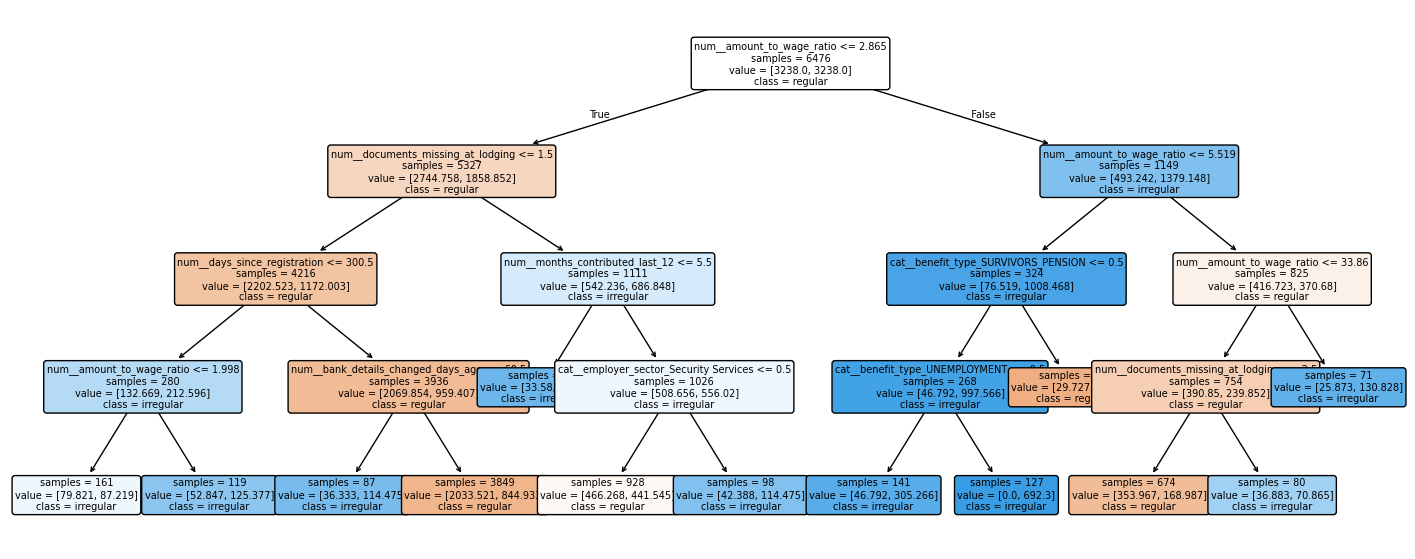

In [52]:
# Draw the tree. named_steps lets you reach inside the pipeline: "model" is the tree, "prep" the preparation.
fitted_tree = tree.named_steps["model"]
feature_names = tree.named_steps["prep"].get_feature_names_out()

plt.figure(figsize=(18, 7))
plot_tree(fitted_tree, feature_names=feature_names, class_names=["regular", "irregular"],
          filled=True, rounded=True, fontsize=7, impurity=False)
plt.show()

Follow a path from the top. Each box shows the question, how many training claims reached that point, and
the class it leans towards. This is something you could show the claims manager tomorrow.

**Your turn (1).** Grow the tree deeper: try `max_depth` of 8 and then `None` (no limit), keeping
everything else the same. What happens to ROC-AUC on the **test** set? Also compute it on the **training**
set. What does the gap between the two tell you?

In [53]:
# Your code here

### Theory: boosting, many small trees that correct each other

One small tree is easy to read but not very accurate. **Gradient boosting** builds hundreds of small trees **in
sequence**:

1. The first tree makes rough predictions.
2. Look at where it's wrong: which claims got scores far from their true answer.
3. The second tree is trained to correct those errors.
4. The third tree corrects what's still wrong, and so on.

The final score adds up the small corrections from all the trees. Each tree only adds a small step (that's the
`learning_rate`), so no single tree can push the result too far. XGBoost and LightGBM are two popular, fast
implementations of this idea.

**The trade-off.** Boosted models are usually the most accurate choice for tables like this one, but they're hard to
explain: you can't draw 400 trees on a whiteboard. Lab 3 shows how to look inside one anyway.

## 8. XGBoost

Gradient-boosted trees build hundreds of small trees, each one correcting the mistakes of the ones before.
On tabular data like this they're usually the strongest off-the-shelf choice.

`scale_pos_weight` plays the same role as `class_weight="balanced"`: it's the ratio of regular to irregular
claims in the training data.

In [54]:
# How many regular claims are there for every irregular one?
n_regular = (y_train == 0).sum()
n_irregular = (y_train == 1).sum()
spw = n_regular / n_irregular
print("regular claims per irregular claim:", round(spw, 1))

regular claims per irregular claim: 9.9


In [55]:
# The settings, one per line:
#   n_estimators=400      build 400 small trees
#   max_depth=4           each tree asks at most 4 questions
#   learning_rate=0.05    each new tree corrects only a little of the remaining error (small = careful)
#   subsample=0.8         each tree sees a random 80% of the claims...
#   colsample_bytree=0.8  ...and a random 80% of the features
xgb = Pipeline([
    ("prep", make_preprocessor(scale_numbers=False)),
    ("model", XGBClassifier(
        n_estimators=400,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=spw,
        eval_metric="logloss",
        random_state=SEED,
        n_jobs=4,
    )),
])
xgb.fit(X_train, y_train)

p_xgb = xgb.predict_proba(X_test)[:, 1]
results["XGBoost"] = scores(y_test, p_xgb)
pd.DataFrame(results).T.round(3)

,accuracy,precision,recall,f1,roc_auc,pr_auc
random baseline,0.825,0.080,0.078,0.079,0.491,0.095
logistic regression,0.754,0.226,0.643,0.335,0.743,0.326
decision tree (depth 4),0.863,0.343,0.457,0.392,0.729,0.395
XGBoost,0.899,0.476,0.527,0.500,0.805,0.590


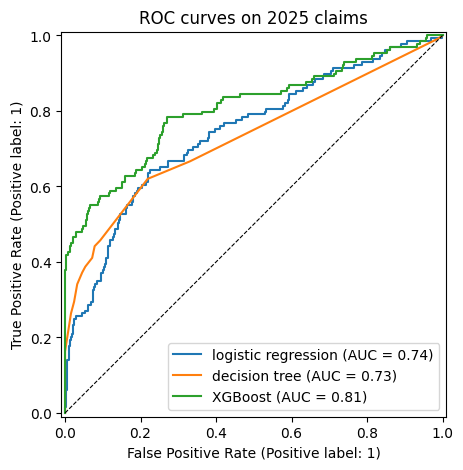

In [56]:
# ROC curves: one line per model. The closer a line hugs the top-left corner, the better the ranking.
fig, ax = plt.subplots(figsize=(5.5, 5))
RocCurveDisplay.from_predictions(y_test, p_lr, name="logistic regression", ax=ax)
RocCurveDisplay.from_predictions(y_test, p_tree, name="decision tree", ax=ax)
RocCurveDisplay.from_predictions(y_test, p_xgb, name="XGBoost", ax=ax)
ax.plot([0, 1], [0, 1], "k--", lw=0.8)     # the diagonal = random guessing
ax.set_title("ROC curves on 2025 claims")
plt.show()

Look at the numbers honestly. On this data XGBoost (eXtreme Gradient Boosting) clearly beats logistic regression: ROC-AUC goes up by
about 0.06, and PR-AUC, which rewards getting the *top* of the ranking right, almost doubles. The top of the
ranking is exactly where the review team works, so this gain matters.

It isn't free, though. A boosted model is harder to explain to an auditor, or to a member who asks why
their claim was held. You'll look inside it in Lab 3. Whether the extra catch is worth the extra explaining
is a **business** decision, and Lab 3 gives you the numbers to make it with.

**Your turn (2).** Try LightGBM (`from lightgbm import LGBMClassifier`) in the same pipeline, with
`n_estimators=400`, `learning_rate=0.05`, `num_leaves=15`, `class_weight="balanced"` and `verbose=-1`.
Add it to `results`. Is it any different from XGBoost?

In [57]:
# Your code here

> **Where we are.** You've trained four models (random baseline, logistic regression, decision tree, XGBoost) on the
> same data and compared them on the same test year. XGBoost ranks claims best. But a score isn't something a claims
> officer can act on.

### Theory: from a score to a decision

A model gives a number. A business needs an **action**. The link between them is a set of **thresholds** that turn
score ranges into bands, each with a clear next step. Choosing those thresholds isn't a modelling question, it's a
business one:

- How many claims can the team review each week? That sets how big the top band can be.
- What does a missed irregular claim cost, compared with an unnecessary check? That sets how cautious to be.

The bands in this section are a first draft. In Lab 3 you'll set the cut-off from the team's real capacity instead.

## 9. From probability to action

A score of 0.87 on its own means nothing to a claims officer. What they need is a decision about what
happens next. Turn the scores into bands the team can act on:

| Score | Action |
|---|---|
| 0.80 and above | Review before payment |
| 0.50 to 0.80 | Check documents |
| below 0.50 | Standard processing |

In [58]:
# A table of the 2025 claims with their scores.
scored = test[["claim_no", "claim_date", "benefit_type", "channel", "amount_claimed_tzs"]].copy()
scored["risk_score"] = p_xgb.round(3)

# pd.cut puts each score into a band. right=False means each band includes its lower edge (0.5 goes to "Check documents").
scored["action"] = pd.cut(
    scored["risk_score"],
    bins=[0, 0.5, 0.8, 1.01],
    labels=["Standard processing", "Check documents", "Review before payment"],
    right=False,
)

# The 10 riskiest claims.
scored.sort_values("risk_score", ascending=False).head(10)

,claim_no,claim_date,benefit_type,channel,amount_claimed_tzs,risk_score,action
6485,CLM-2025-007058,2025-01-03,UNEMPLOYMENT,ONLINE,1572400.0,0.998,Review before payment
7708,CLM-2025-000307,2025-12-07,UNEMPLOYMENT,BRANCH,1251900.0,0.998,Review before payment
6502,CLM-2025-003444,2025-01-06,UNEMPLOYMENT,EMPLOYER_HR,1415900.0,0.997,Review before payment
7636,CLM-2025-009350,2025-11-17,UNEMPLOYMENT,BRANCH,1213600.0,0.996,Review before payment
7067,CLM-2025-010320,2025-06-09,UNEMPLOYMENT,EMPLOYER_HR,2283900.0,0.995,Review before payment
7353,CLM-2025-003231,2025-08-29,UNEMPLOYMENT,BRANCH,1374300.0,0.995,Review before payment
7613,CLM-2025-001389,2025-11-13,UNEMPLOYMENT,BRANCH,1726400.0,0.994,Review before payment
7460,CLM-2025-011481,2025-09-30,UNEMPLOYMENT,ONLINE,4804000.0,0.994,Review before payment
7617,CLM-2025-009500,2025-11-13,UNEMPLOYMENT,EMPLOYER_HR,2452700.0,0.991,Review before payment
7774,CLM-2025-008857,2025-12-29,UNEMPLOYMENT,BRANCH,1355300.0,0.990,Review before payment


In [59]:
# For each band: how many claims, what share of all claims, and what share really were irregular.
scored["irregular"] = y_test.values

summary = scored.groupby("action", observed=True).agg(
    claims=("claim_no", "count"),
    irregular_rate=("irregular", "mean"),
)
summary["share_of_claims"] = summary["claims"] / len(scored)
summary.round(3)

,claims,irregular_rate,share_of_claims
action,,,
Standard processing,1197,0.051,0.893
Check documents,91,0.198,0.068
Review before payment,52,0.962,0.039


Read the last table carefully, because it's the one you'd take to a manager. The top band is small, and a
large share of what's in it really is irregular. That's where scarce reviewer time pays off.

Notice what the output says: *Review before payment*, not *Fraud*. The model ranks. A person decides.
That matters for fairness to members, and it's also the only honest description of what the model can do.

**Your turn (3).** Pick one high-scoring claim from the table above and write two or three sentences, in plain
language, that a reviewer could use to explain *why* it was flagged. Look at its row in `test`. You'll do this
more rigorously in Lab 3.

*Your answer here.*

> **Where we are.** The scores are now bands with actions, and you've seen how many claims, and what share of real
> problems, land in each band. The last step saves the scored test claims so Lab 3 can pick up from here.

## 10. Save your work for Lab 3

In [60]:
Path("outputs").mkdir(exist_ok=True)

# The scored 2025 claims.
scored.to_csv("outputs/lab1_scored_2025_claims.csv", index=False)

# The comparison table.
results_table = pd.DataFrame(results).T.round(4)
results_table.to_csv("outputs/lab1_model_results.csv")
print("saved")

saved


## Looking back, looking ahead

**What you did in this lab.** You built a claims risk score the careful way: you looked at the target, found which
blanks carry meaning, checked for signal, engineered features with a reason behind each, split by time, set a baseline,
and trained three models of increasing complexity, each judged on the same 2025 claims. Then you turned scores into
action bands.

**The ideas to carry forward.**

- Accuracy misleads when the problem class is rare.
- Test on data the model has never seen, split the way it will be used.
- Every model must beat a baseline.
- More complex models are only worth it if they earn their place, and they cost you explainability.
- The model ranks; a person decides.

**What happens next.** Lab 2 switches to a different kind of question: with no target column at all, what natural
groups of members and employers exist? Then Lab 3 comes back to these models and asks whether you can trust the
winner.

---

## Answers to the "Your turn" exercises

**(1)** Deeper trees. First depth 8:

In [61]:
tree_8 = Pipeline([
    ("prep", make_preprocessor(scale_numbers=False)),
    ("model", DecisionTreeClassifier(max_depth=8, min_samples_leaf=50, class_weight="balanced", random_state=SEED)),
])
tree_8.fit(X_train, y_train)

auc_train = roc_auc_score(y_train, tree_8.predict_proba(X_train)[:, 1])
auc_test = roc_auc_score(y_test, tree_8.predict_proba(X_test)[:, 1])
print(f"max_depth=8:    train AUC {auc_train:.3f}   test AUC {auc_test:.3f}")

max_depth=8:    train AUC 0.843   test AUC 0.759


In [62]:
# No depth limit, and leaves as small as 1 claim.
tree_full = Pipeline([
    ("prep", make_preprocessor(scale_numbers=False)),
    ("model", DecisionTreeClassifier(max_depth=None, min_samples_leaf=1, class_weight="balanced", random_state=SEED)),
])
tree_full.fit(X_train, y_train)

auc_train = roc_auc_score(y_train, tree_full.predict_proba(X_train)[:, 1])
auc_test = roc_auc_score(y_test, tree_full.predict_proba(X_test)[:, 1])
print(f"max_depth=None: train AUC {auc_train:.3f}   test AUC {auc_test:.3f}")

max_depth=None: train AUC 1.000   test AUC 0.645


With no depth limit the tree memorises the training data (training AUC close to 1.0) and does worse on
2025 claims. That gap is **overfitting**: the model learned the noise in past claims rather than patterns that
carry forward. Limiting depth and requiring a minimum number of claims per leaf are two ways to stop it.

**(2)** LightGBM:

In [63]:
from lightgbm import LGBMClassifier

lgbm = Pipeline([
    ("prep", make_preprocessor(scale_numbers=False)),
    ("model", LGBMClassifier(n_estimators=400, learning_rate=0.05, num_leaves=15, class_weight="balanced",
                             random_state=SEED, verbose=-1)),
])
lgbm.fit(X_train, y_train)

results["LightGBM"] = scores(y_test, lgbm.predict_proba(X_test)[:, 1])
pd.DataFrame(results).T.round(3)

,accuracy,precision,recall,f1,roc_auc,pr_auc
random baseline,0.825,0.080,0.078,0.079,0.491,0.095
logistic regression,0.754,0.226,0.643,0.335,0.743,0.326
decision tree (depth 4),0.863,0.343,0.457,0.392,0.729,0.395
XGBoost,0.899,0.476,0.527,0.500,0.805,0.590
LightGBM,0.911,0.545,0.465,0.502,0.797,0.575


Very close to XGBoost. On most tabular problems the two land within a hair of each other. Choose whichever your
team can support, and don't spend a week tuning the difference away.

**(3)** For example: *"Flagged because the bank details were changed 12 days before the claim, two documents
were missing when it was lodged, and the amount is 4.8 times the member's recent monthly wage."* Notice that a
good explanation uses the member's own facts, not model jargon.